In [1]:
# ruff: noqa: F405
from pathlib import Path
from pickle import dump, load

import anndata as ad
import numpy as np
from ingest import psc_ds, run_nmf, run_proc_per_ds
from matplotlib import pyplot as plt
from plotnine import *  # noqa: F403

import apl
import spatialpeeler as sP
from spatialpeeler.diag import comp_sparsity, geom_point_sp, sweep_uns

# set figure dpi to 300 for export to notebook
plt.rcParams["figure.dpi"] = 300
RAND_SEED = 28

In [2]:
# load dataset + run NMF
if (pth := Path("../.cache/psc.pkl")).exists():
    with open(pth, "rb") as f:
        psc = load(f)
else:
    adatas = psc_ds(
        Path("../data/psc-visium"),
    )
    run_proc_per_ds(adatas)

    psc = ad.concat(adatas, label="sample_id", index_unique="_")

    run_nmf(psc, 30, RAND_SEED)

    with open(pth, "wb") as f:
        dump(psc, f)
print(psc)

AnnData object with n_obs × n_vars = 39936 × 36601
    obs: 'cell', 'group', 'sample_id'
    obsm: 'spatial', 'X_nmf'
    varm: 'X_nmf'
    layers: 'counts'


with our processed data, we proceed with the factor-wise regression step of spatialPeeler

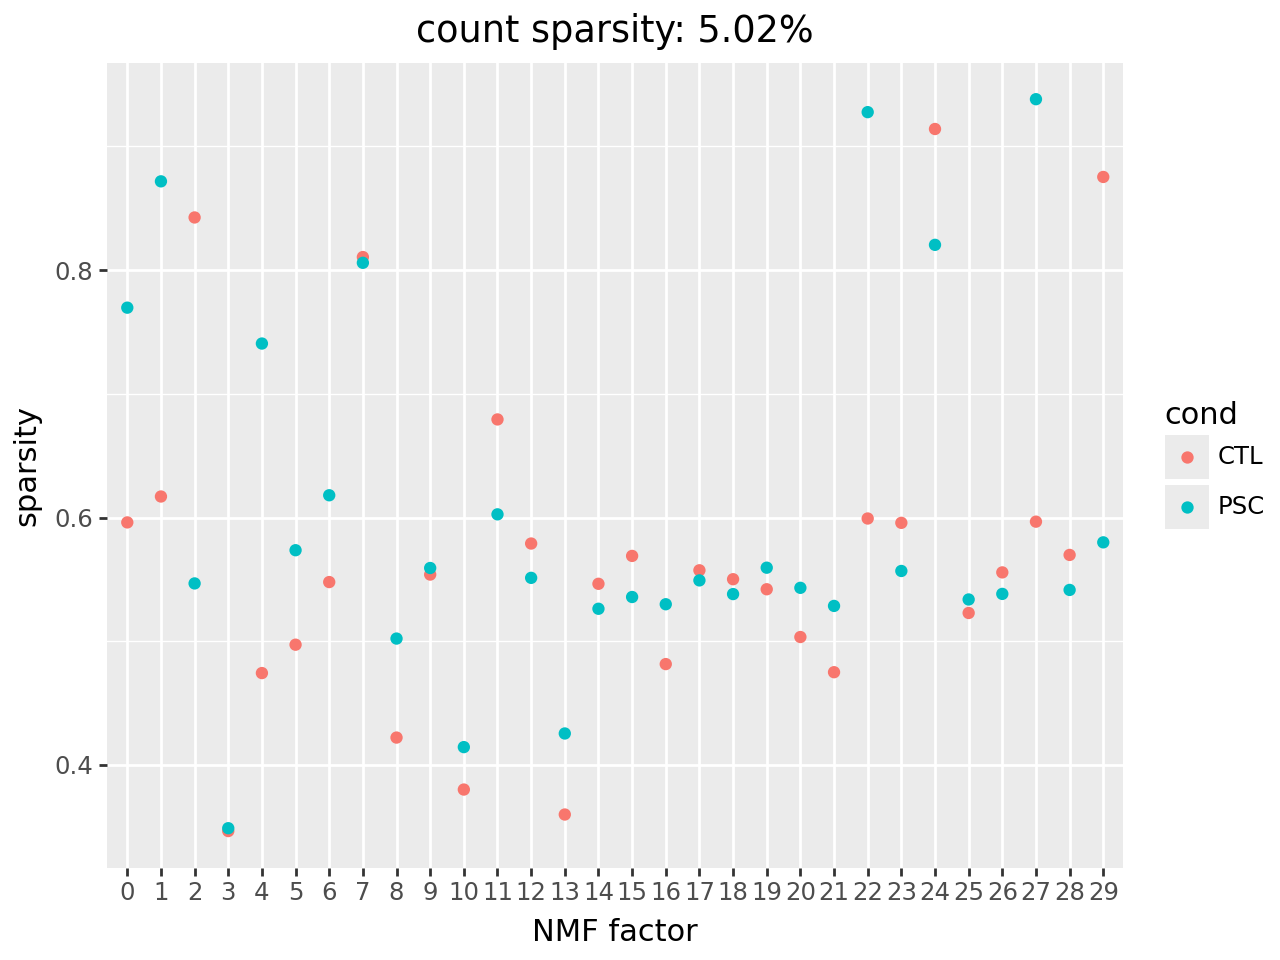

In [3]:
X_spars = psc.X.nnz / np.prod(psc.X.shape)  # ty:ignore[unresolved-attribute]
(
    comp_sparsity(psc.obsm["X_nmf"], cond=psc.obs["group"])
    >> ggplot()
    + aes(x="column", colour="cond", y="sparsity")
    + geom_point()
    + labs(x="NMF factor", title=f"count sparsity: {X_spars * 100:.02f}%")
).show()

In [4]:
# run factor-wise regression step
for k in range(psc.obsm["X_nmf"].shape[1]):
    sP.run_fact_reg(psc, "group", "CTL", k, f"sP_p_hat_k={k:02}", X_key="X_nmf")

print(psc)

AnnData object with n_obs × n_vars = 39936 × 36601
    obs: 'cell', 'group', 'sample_id'
    uns: 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_hat_k=18', 'sP_p_hat_k=19', 'sP_p_hat_k=20', 'sP_p_hat_k=21', 'sP_p_hat_k=22', 'sP_p_hat_k=23', 'sP_p_hat_k=24', 'sP_p_hat_k=25', 'sP_p_hat_k=26', 'sP_p_hat_k=27', 'sP_p_hat_k=28', 'sP_p_hat_k=29'
    obsm: 'spatial', 'X_nmf', 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_hat_k=18', 'sP_p_hat_k=19', 'sP_p_hat_k=20', 'sP_p_

we now assess our resulting regression outputs distributions \
we can extract and collate the model betas and other statistics using the sweep_uns function

/workspaces/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log


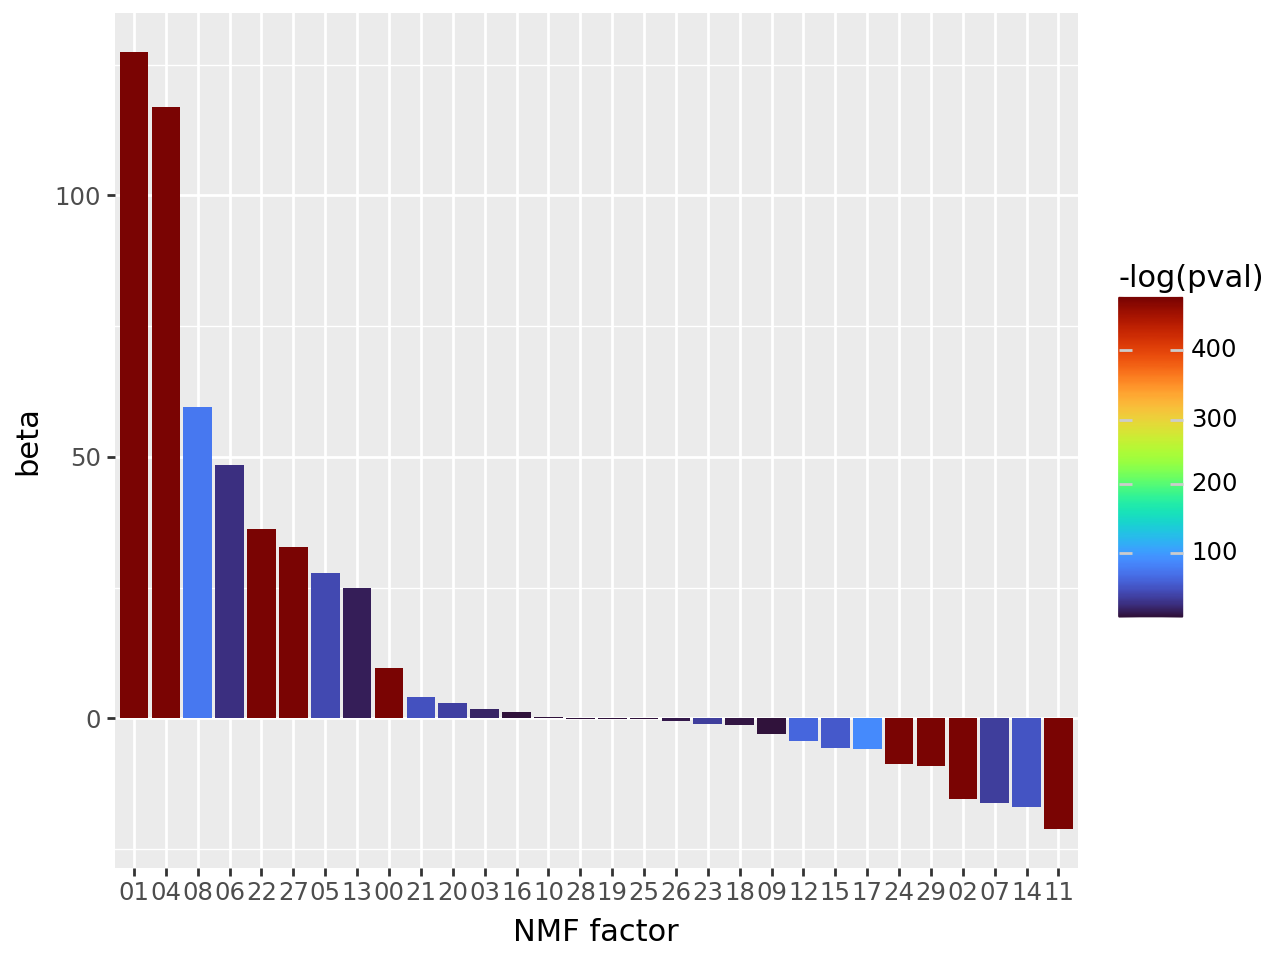

In [5]:
(
    sweep_uns(psc, "sP_p_hat_k={k}")
    >> ggplot()
    + aes(x="reorder(k, -beta)", fill="-np.log(pval)", y="beta")
    + geom_col()
    + labs(fill="-log(pval)", x="NMF factor")
    + scale_fill_cmap("turbo")
).show()

In [6]:
def pl_k_sp(adata: ad.AnnData, k_oi: int) -> ggplot:
    obsm_sl_oi = f"sP_p_hat_k={k_oi:02}"

    plo = apl.PlotAdata(adata)

    pl1 = (
        plo
        + aes(colour=apl.obsm(obsm_sl_oi, sP.PAT_KEY))
        + labs(colour="p_hat")
        + scale_colour_cmap("YlGnBu", limits=(0, 1))
        + aes(x=apl.obsm("spatial", "x"), y=apl.obsm("spatial", "y"))
        + geom_point_sp(size_in_px=2, alpha=0.5)
        + facet_wrap([apl.obs("group"), apl.obs("sample_id")], ncol=2, dir="v", shrink=False)
        + theme(
            axis_text=element_blank(),
            axis_ticks=element_blank(),
            strip_text=element_blank(),
            panel_background=element_blank(),
            plot_background=element_blank(),
            panel_grid=element_blank(),
        )
    )
    pl2 = (
        plo
        + aes(
            x=apl.obsm("X_nmf", k_oi),
            y=apl.obsm(obsm_sl_oi, sP.PAT_KEY),
            colour=apl.obs("group"),
        )
        + geom_point(alpha=0.5, shape=".")
        + labs(y="p_hat")
        + scale_colour_discrete()
    )
    return pl1 | pl2

we can see that factors 1 and 4 have strong gain-of-function profile \
we plot their distributions below:

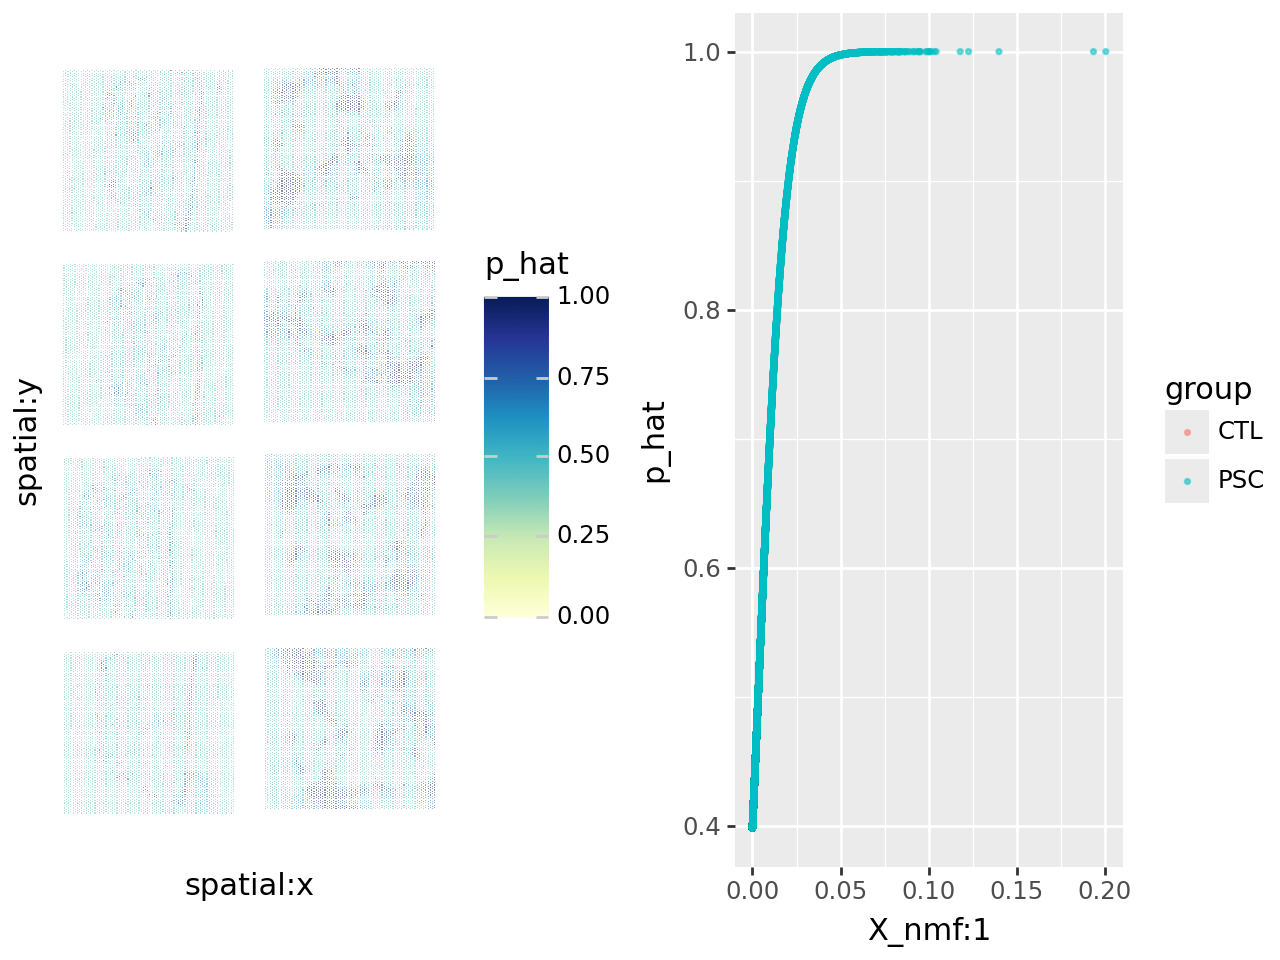

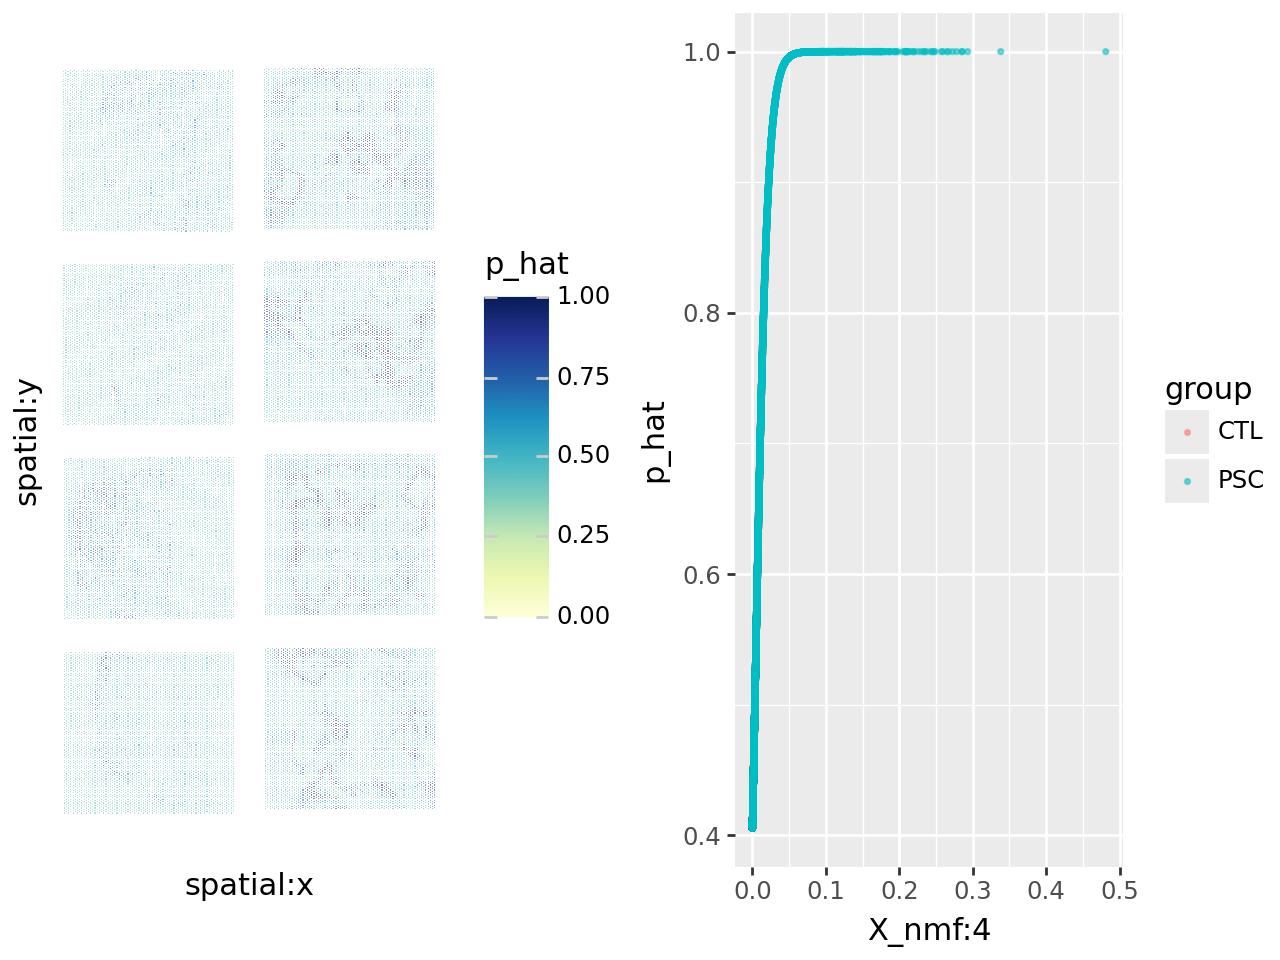

In [7]:
pl_k_sp(psc, 1).show()
pl_k_sp(psc, 4).show()

we can also see that factor 11 showed a strong loss-of-function profile \
we plot its distribution below:

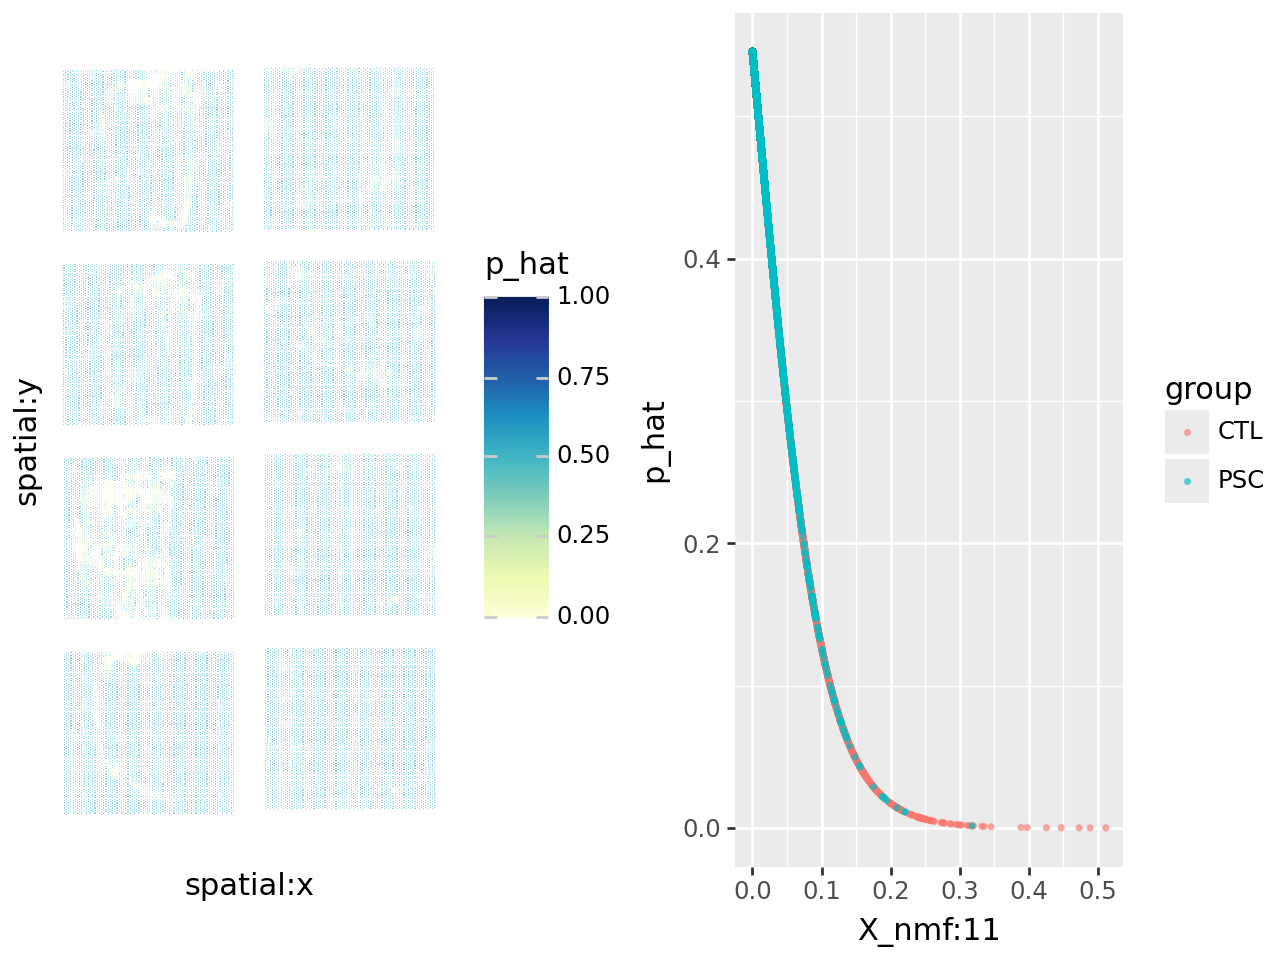

In [8]:
pl_k_sp(psc, 11).show()